# Análise exploratória — Guitar Chords Finger Positions


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data" / "raw" / "chord-fingers.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "raw" / "chord-fingers.csv"
SELECTED_CLASSES = ("maj", "m", "dim", "7", "maj7", "m7")
ALLOWED_FINGERS = {"x", "0", "1", "2", "3", "4"}


## Visão geral


In [2]:
data = pd.read_csv(DATA_PATH, sep=";", dtype="string", keep_default_na=False)
data = data.replace("", pd.NA)

print(f"Instâncias: {data.shape[0]}")
print(f"Atributos: {data.shape[1]}")
data.head()


Instâncias: 2632
Atributos: 5


,CHORD_ROOT,CHORD_TYPE,CHORD_STRUCTURE,FINGER_POSITIONS,NOTE_NAMES
0,A#,13,1;3;5;b7;9;11;13,"x,1,0,2,3,4","A#,C##,G#,B#,F##"
1,A#,13,1;3;5;b7;9;11;13,"4,x,3,2,1,1","A#,G#,B#,C##,F##"
2,A#,13,1;3;5;b7;9;11;13,"1,x,1,2,3,4","A#,G#,C##,F##,B#"
3,A#,7(#9),1;3;5;b7;#9,"x,1,0,2,4,3","A#,C##,G#,B##,E#"
4,A#,7(#9),1;3;5;b7;#9,"2,1,3,3,3,x","A#,C##,G#,B##,E#"


In [3]:
attribute_summary = pd.DataFrame({
    "type": data.dtypes.astype(str),
    "unique_values": data.nunique(dropna=True),
    "missing_values": data.isna().sum(),
})
attribute_summary


,type,unique_values,missing_values
CHORD_ROOT,string,18,0
CHORD_TYPE,string,42,0
CHORD_STRUCTURE,string,42,0
FINGER_POSITIONS,string,769,0
NOTE_NAMES,string,2152,0


In [4]:
# Valores possíveis dos atributos com baixa cardinalidade.
for column in ["CHORD_ROOT", "CHORD_TYPE", "CHORD_STRUCTURE"]:
    values = sorted(data[column].dropna().unique())
    print(f"{column} ({len(values)}): {values}\n")


CHORD_ROOT (18): ['A', 'A#', 'Ab', 'B', 'Bb', 'C', 'C#', 'Cb', 'D', 'D#', 'Db', 'E', 'Eb', 'F', 'F#', 'G', 'G#', 'Gb']

CHORD_TYPE (42): ['+(#11)', '11', '13', '13(#11)', '13(#9)', '13(b9)', '5', '6', '6(#11)', '6/9', '7', '7(#11)', '7(#5)', '7(#9)', '7(b13)', '7(b9)', '7b5', '7sus4', '9', '9(#11)', '9(#5)', '9b5', 'add9', 'aug', 'dim', 'dim7', 'm', 'm(maj7)', 'm(maj9)', 'm11', 'm13', 'm6', 'm6/9', 'm7', 'm7b5', 'm9', 'maj', 'maj13', 'maj7', 'maj9', 'sus2', 'sus4']

CHORD_STRUCTURE (42): ['1;2;5', '1;3;#5', '1;3;#5;#11', '1;3;#5;b7', '1;3;#5;b7;9', '1;3;5', '1;3;5;6', '1;3;5;6;#11', '1;3;5;6;9', '1;3;5;7', '1;3;5;7;9', '1;3;5;7;9;11;13', '1;3;5;9', '1;3;5;b7', '1;3;5;b7;#11', '1;3;5;b7;#9', '1;3;5;b7;#9;11;13', '1;3;5;b7;9', '1;3;5;b7;9;#11', '1;3;5;b7;9;#11;13', '1;3;5;b7;9;11', '1;3;5;b7;9;11;13', '1;3;5;b7;b13', '1;3;5;b7;b9', '1;3;5;b7;b9;11;13', '1;3;b5;b7', '1;3;b5;b7;9', '1;4;5', '1;4;5;b7', '1;5', '1;b3;5', '1;b3;5;6', '1;b3;5;6;9', '1;b3;5;7', '1;b3;5;7;9', '1;b3;5;b7', '1;b3;

## Distribuição das classes


,CHORD_TYPE,records,percentage
0,7,208,7.9
1,maj,203,7.71
2,m7,177,6.72
3,m,154,5.85
4,dim7,142,5.4
5,maj7,137,5.21
6,6,134,5.09
7,13,113,4.29
8,5,108,4.1
9,9,105,3.99


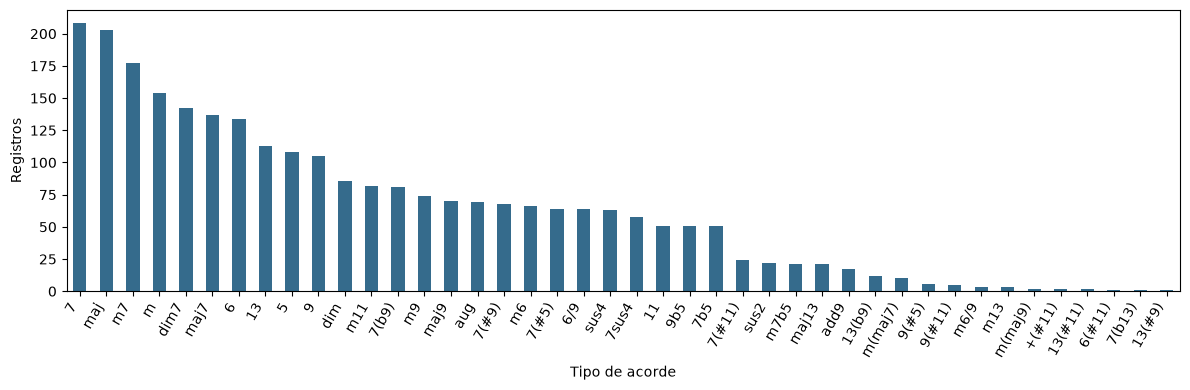

In [5]:
class_distribution = (
    data["CHORD_TYPE"].value_counts().rename_axis("CHORD_TYPE").reset_index(name="records")
)
class_distribution["percentage"] = (
    100 * class_distribution["records"] / len(data)
).round(2)
display(class_distribution)

ax = class_distribution.plot.bar(
    x="CHORD_TYPE", y="records", figsize=(12, 4), legend=False, color="#356b8c"
)
ax.set(xlabel="Tipo de acorde", ylabel="Registros")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


,records,percentage
CHORD_TYPE,,
maj,203,21.04
m,154,15.96
dim,86,8.91
7,208,21.55
maj7,137,14.2
m7,177,18.34


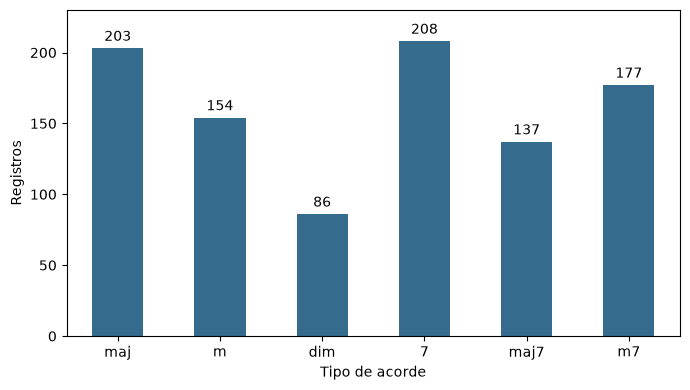

In [6]:
selected = data.loc[data["CHORD_TYPE"].isin(SELECTED_CLASSES)].copy()
selected_distribution = (
    selected["CHORD_TYPE"].value_counts().reindex(SELECTED_CLASSES).rename("records").to_frame()
)
selected_distribution["percentage"] = (
    100 * selected_distribution["records"] / len(selected)
).round(2)
display(selected_distribution)

ax = selected_distribution["records"].plot.bar(figsize=(7, 4), color="#356b8c")
ax.bar_label(ax.containers[0], padding=3)
ax.set(xlabel="Tipo de acorde", ylabel="Registros", ylim=(0, 230))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Qualidade dos dados


In [7]:
duplicate_summary = pd.DataFrame({
    "dataset": ["Completo", "Seis classes"],
    "records": [len(data), len(selected)],
    "duplicate_group_members": [data.duplicated(keep=False).sum(), selected.duplicated(keep=False).sum()],
    "duplicates_after_first": [data.duplicated().sum(), selected.duplicated().sum()],
}).set_index("dataset")
display(duplicate_summary)

duplicate_rows = data.loc[data.duplicated(keep=False)].copy()
duplicate_rows.insert(0, "source_row", duplicate_rows.index + 2)
duplicate_rows.sort_values(list(data.columns))


,records,duplicate_group_members,duplicates_after_first
dataset,,,
Completo,2632,22,11
Seis classes,965,12,6


,source_row,CHORD_ROOT,CHORD_TYPE,CHORD_STRUCTURE,FINGER_POSITIONS,NOTE_NAMES
1436,1438,B,7,1;3;5;b7,"x,2,1,3,0,4","B,D#,A,B,F#"
1442,1444,B,7,1;3;5;b7,"x,2,1,3,0,4","B,D#,A,B,F#"
1485,1487,B,m,1;b3;5,"x,1,3,4,2,1","B,F#,B,D,F#"
1491,1493,B,m,1;b3;5,"x,1,3,4,2,1","B,F#,B,D,F#"
1612,1614,C,7,1;3;5;b7,"x,3,2,4,1,x","C,E,Bb,C"
1615,1617,C,7,1;3;5;b7,"x,3,2,4,1,x","C,E,Bb,C"
1584,1586,C,9,1;3;5;b7;9,"x,2,1,3,3,3","C,E,Bb,D,G"
1585,1587,C,9,1;3;5;b7;9,"x,2,1,3,3,3","C,E,Bb,D,G"
1720,1722,C,m7,1;b3;5;b7,"x,2,1,3,4,x","C,Eb,Bb,Eb"
1721,1723,C,m7,1;b3;5;b7,"x,2,1,3,4,x","C,Eb,Bb,Eb"


In [8]:
finger_positions = data["FINGER_POSITIONS"].fillna("").str.split(",")
valid_positions = finger_positions.map(
    lambda values: len(values) == 6 and all(value in ALLOWED_FINGERS for value in values)
)
finger_symbols = pd.Series(
    [symbol for positions in finger_positions for symbol in positions], dtype="string"
).value_counts().sort_index()

print("Formato: seis símbolos separados por vírgula, da corda E grave à mais aguda.")
print("Símbolos: x=abafada, 0=solta, 1=indicador, 2=médio, 3=anelar, 4=mínimo.")
print(f"Posições distintas: {data['FINGER_POSITIONS'].nunique()}")
print(f"Registros fora do formato: {(~valid_positions).sum()}")
finger_symbols.rename("occurrences").to_frame()


Formato: seis símbolos separados por vírgula, da corda E grave à mais aguda.
Símbolos: x=abafada, 0=solta, 1=indicador, 2=médio, 3=anelar, 4=mínimo.
Posições distintas: 769
Registros fora do formato: 0


,occurrences
0,870
1,4246
2,2008
3,2513
4,1678
x,4477


## Ambiguidades de raiz e posição dos dedos


In [9]:
full_combinations = (
    data.groupby(["CHORD_ROOT", "FINGER_POSITIONS"])["CHORD_TYPE"]
    .agg(record_count="size", class_count="nunique", classes=lambda values: " | ".join(sorted(values.unique())))
    .reset_index()
)
selected_combinations = (
    selected.groupby(["CHORD_ROOT", "FINGER_POSITIONS"])["CHORD_TYPE"]
    .agg(record_count="size", class_count="nunique", classes=lambda values: " | ".join(sorted(values.unique())))
    .reset_index()
)
full_ambiguous = full_combinations.loc[full_combinations["class_count"] > 1]
selected_ambiguous = selected_combinations.loc[selected_combinations["class_count"] > 1]

ambiguity_summary = pd.DataFrame({
    "dataset": ["Completo", "Seis classes"],
    "distinct_combinations": [len(full_combinations), len(selected_combinations)],
    "ambiguous_combinations": [len(full_ambiguous), len(selected_ambiguous)],
    "affected_records": [full_ambiguous["record_count"].sum(), selected_ambiguous["record_count"].sum()],
}).set_index("dataset")
display(ambiguity_summary)
selected_ambiguous.reset_index(drop=True)


,distinct_combinations,ambiguous_combinations,affected_records
dataset,,,
Completo,2260,237,567
Seis classes,927,31,63


,CHORD_ROOT,FINGER_POSITIONS,record_count,class_count,classes
0,A,"x,0,1,3,4,2",2,2,m | maj
1,A,"x,2,1,3,x,x",2,2,7 | m7
2,A,"x,x,x,2,1,0",3,2,m | maj
3,Ab,"1,x,2,3,x,x",2,2,7 | maj7
4,B,"x,x,1,2,4,3",2,2,dim | maj
5,B,"x,x,x,3,2,1",2,2,dim | m
6,Bb,"x,x,1,1,1,4",2,2,maj | maj7
7,Bb,"x,x,x,2,1,3",2,2,7 | dim
8,Bb,"x,x,x,3,2,1",2,2,7 | m
9,C,"x,x,1,1,1,3",2,2,7 | maj7
